# 05 — Reference Control and Training-Budget Validation

## Robustness-Enhanced Vision-Language-Action Learning

**Module:** Deep Learning (`CT100-3-M-DL`)  
**Programme:** Master in Artificial Intelligence  
**Framework:** Hugging Face LeRobot `v0.6.1`  
**Benchmark:** LIBERO-Spatial  
**Diagnostic focus:** released-reference control → training-budget curve → trainability-scope audit → frozen final-training decision

---

### Why this notebook exists

Notebook 04 completed the full pilot evaluation, but the absolute closed-loop success rates of the fine-tuned models were very low.

That creates a **floor-effect risk**: when nearly every episode fails, small differences between robustness variants are not strong evidence of useful generalization.

Notebook 05 therefore does **not** tune on the OOD conditions observed in Notebook 04. Instead, it returns to the in-distribution E0 condition and asks two narrower questions:

1. **Evaluator control:** does the released `lerobot/smolvla_libero` reference checkpoint succeed under the same closed-loop evaluator?
2. **Training-regime adequacy:** how much E0 success is recovered as M1 receives a substantially larger fine-tuning budget, and does broader parameter trainability help?

The objective is to freeze a defensible final training regime **before** retraining M1 / M2-L / M2-E / M2-LE.

---

### Scientific separation from Notebook 04

Notebook 04 remains a valid **pilot robustness evaluation**.

Its OOD results are **not used to select the new training configuration**.

Notebook 05 selects the training regime using only:

- E0 / original-language closed-loop success,
- the released M0 reference as an external control,
- offline validation loss as a secondary diagnostic,
- training stability and computational cost.

This reduces the risk of tuning directly against the final OOD test conditions.

## 1. Predeclared diagnostic design

### Reference control

- **M0 released reference:** `lerobot/smolvla_libero`
- First reproduce the known task-0 / seed-42 control from Notebook 01.
- Then evaluate M0 on **10 tasks × 3 E0 episodes = 30 episodes**.

### Standard training-budget trajectory

One new M1 training trajectory is run from the pinned `smolvla_base` initialization for **25,000 steps**.

Checkpoints are saved at:

- 1,500
- 5,000
- 10,000
- 20,000
- 25,000 steps

Using a single trajectory makes the training-budget curve compute-efficient and prevents repeated independent restarts from adding unnecessary stochastic variation.

### Broader-trainability comparison

A second 25,000-step M1 run uses a broader trainable scope:

- `freeze_vision_encoder = False`
- `train_expert_only = False`
- `train_state_proj = True`

The optimizer and data remain fixed so that the principal changed factor is **which parts of SmolVLA are allowed to adapt**.

### Screening evaluation

Every candidate checkpoint receives the same:

`10 tasks × 3 E0 episodes = 30 closed-loop episodes`

No language or visual OOD perturbation is used for configuration selection.

## 2. Environment, paths and fixed diagnostic rules

In [2]:
import os

os.environ.setdefault("GALLIUM_DRIVER", "d3d12")
os.environ.setdefault("MESA_D3D12_DEFAULT_ADAPTER_NAME", "NVIDIA")
os.environ.setdefault("MUJOCO_GL", "glfw")

from pathlib import Path
from copy import deepcopy
from datetime import datetime
import gc
import hashlib
import json
import math
import random
import shutil
import subprocess
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch.utils.data import DataLoader, Subset

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

DATASET_REPO_ID = "lerobot/libero"
BASE_MODEL_REPO_ID = "lerobot/smolvla_base"
REFERENCE_MODEL_REPO_ID = "lerobot/smolvla_libero"
LIBERO_SUITE = "libero_spatial"
VIDEO_BACKEND = "pyav"

DIAGNOSTIC_SEED = 42
BATCH_SIZE = 4

STANDARD_CHECKPOINT_STEPS = [
    1500,
    5000,
    10000,
    20000,
    25000,
]

MAX_TRAINING_STEPS = max(
    STANDARD_CHECKPOINT_STEPS
)

BROAD_TRAINING_STEPS = 25000

E0_EPISODES_PER_TASK = 3

VAL_BATCH_SIZE = 4

GRAD_CLIP_NORM = 10.0
WARMUP_FRACTION = 0.10
MIN_LR_RATIO = 0.025
LOG_EVERY = 100

# Predeclared practical adequacy gate.
# A candidate is considered ready for final robustness retraining only if:
#   (a) E0 success >= 20%, and
#   (b) it retains >= 80% of released-reference M0 E0 success.
ABSOLUTE_MIN_E0_SUCCESS = 0.20
REFERENCE_RETENTION_TARGET = 0.80

# If multiple adequate candidates differ by only one success in the
# 30-episode screen, prefer the lower-compute candidate.
PRACTICAL_TIE_SUCCESS_COUNT = 1


def find_repo_root(start: Path) -> Path:
    current = start.resolve()

    for candidate in [current, *current.parents]:
        if (candidate / ".git").exists():
            return candidate

    if current.name == "notebooks":
        return current.parent

    return current


REPO_ROOT = find_repo_root(
    Path.cwd()
)

CONFIG_DIR = (
    REPO_ROOT / "configs"
)

EXPERIMENT_CONFIG_DIR = (
    CONFIG_DIR / "experiments"
)

RESULTS_DIR = (
    REPO_ROOT / "results"
)

METRICS_DIR = (
    RESULTS_DIR
    / "metrics"
    / "training_regime_validation"
)

FIGURES_DIR = (
    RESULTS_DIR
    / "figures"
    / "training_regime_validation"
)

TRAINING_OUTPUT_DIR = (
    REPO_ROOT
    / "experiments"
    / "training_regime_validation"
)

for directory in [
    EXPERIMENT_CONFIG_DIR,
    METRICS_DIR,
    FIGURES_DIR,
    TRAINING_OUTPUT_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


def git_sha(repo_root: Path):
    try:
        return subprocess.check_output(
            ["git", "rev-parse", "HEAD"],
            cwd=repo_root,
            text=True,
        ).strip()
    except Exception:
        return None


PROJECT_GIT_SHA = git_sha(
    REPO_ROOT
)

environment_summary = {
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "device": DEVICE,
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
    "diagnostic_seed": DIAGNOSTIC_SEED,
    "standard_max_steps": MAX_TRAINING_STEPS,
    "broad_max_steps": BROAD_TRAINING_STEPS,
    "e0_episodes_per_candidate": (
        10 * E0_EPISODES_PER_TASK
    ),
    "project_git_sha": PROJECT_GIT_SHA,
}

display(
    pd.DataFrame(
        [environment_summary]
    ).T.rename(
        columns={0: "Value"}
    )
)

assert torch.cuda.is_available(), (
    "Notebook 05 is configured for the validated CUDA environment."
)

,Value
python,3.12.14
torch,2.11.0+cu128
cuda_available,True
device,cuda
gpu,NVIDIA GeForce RTX 5090
diagnostic_seed,42
standard_max_steps,25000
broad_max_steps,25000
e0_episodes_per_candidate,30
project_git_sha,bf3d723e97e3e95b5b0d391efe9e13184f620a05


## 3. Load Notebook 01 / 03 / 04 evidence and freeze inputs

In [3]:
NOTEBOOK01_SUMMARY_PATH = (
    REPO_ROOT
    / "results"
    / "metrics"
    / "baseline_reproduction"
    / "baseline_reproduction_summary.json"
)

NOTEBOOK03_SUMMARY_PATH = (
    REPO_ROOT
    / "results"
    / "metrics"
    / "tuning_final_training"
    / "notebook03_summary.json"
)

NOTEBOOK04_SUMMARY_PATH = (
    REPO_ROOT
    / "results"
    / "metrics"
    / "evaluation_critical_analysis"
    / "notebook04_summary.json"
)

for path in [
    NOTEBOOK01_SUMMARY_PATH,
    NOTEBOOK03_SUMMARY_PATH,
    NOTEBOOK04_SUMMARY_PATH,
]:
    assert path.exists(), (
        f"Required prior summary missing: {path}"
    )


with open(
    NOTEBOOK01_SUMMARY_PATH,
    "r",
) as f:
    notebook01_summary = json.load(f)


with open(
    NOTEBOOK03_SUMMARY_PATH,
    "r",
) as f:
    notebook03_summary = json.load(f)


with open(
    NOTEBOOK04_SUMMARY_PATH,
    "r",
) as f:
    notebook04_summary = json.load(f)


assert notebook01_summary["g0_pass"]
assert notebook03_summary["status"] == "PASS"
assert notebook04_summary["status"] == "PASS"


DATASET_REVISION = (
    notebook03_summary[
        "dataset_revision"
    ]
)

BASE_MODEL_REVISION = (
    notebook03_summary[
        "base_model_revision"
    ]
)

REFERENCE_MODEL_REVISION = (
    notebook01_summary[
        "model_revision"
    ]
)

SELECTED_OPTIMIZER = (
    notebook03_summary[
        "selected_optimizer"
    ]
)

LEARNING_RATE = float(
    SELECTED_OPTIMIZER[
        "learning_rate"
    ]
)

WEIGHT_DECAY = float(
    SELECTED_OPTIMIZER[
        "weight_decay"
    ]
)

frozen_split_path = (
    REPO_ROOT
    / notebook03_summary[
        "split_file"
    ]
)

validation_subset_path = (
    REPO_ROOT
    / notebook03_summary[
        "validation_subset"
    ]
)

assert frozen_split_path.exists()
assert validation_subset_path.exists()

frozen_split_df = pd.read_csv(
    frozen_split_path
)

validation_subset_df = pd.read_csv(
    validation_subset_path
)

frozen_split_df["split"] = (
    frozen_split_df["split"]
    .astype(str)
    .str.lower()
    .str.strip()
    .replace({
        "val": "validation",
        "valid": "validation",
    })
)

train_ids = sorted(
    frozen_split_df.loc[
        frozen_split_df["split"]
        == "train",
        "episode_index",
    ].astype(int).tolist()
)

validation_ids = sorted(
    frozen_split_df.loc[
        frozen_split_df["split"]
        == "validation",
        "episode_index",
    ].astype(int).tolist()
)

assert len(train_ids) == 346
assert len(validation_ids) == 86
assert set(train_ids).isdisjoint(
    validation_ids
)

prior_evidence = {
    "Notebook 01 G0": notebook01_summary["g0_pass"],
    "Notebook 03": notebook03_summary["status"],
    "Notebook 04": notebook04_summary["status"],
    "dataset_revision": DATASET_REVISION,
    "base_model_revision": BASE_MODEL_REVISION,
    "reference_model_revision": REFERENCE_MODEL_REVISION,
    "selected_learning_rate": LEARNING_RATE,
    "selected_weight_decay": WEIGHT_DECAY,
    "train_episodes": len(train_ids),
    "validation_episodes": len(validation_ids),
}

display(
    pd.DataFrame(
        [prior_evidence]
    ).T.rename(
        columns={0: "Value"}
    )
)

print("PRIOR EVIDENCE + FROZEN INPUTS: PASS")

,Value
Notebook 01 G0,True
Notebook 03,PASS
Notebook 04,PASS
dataset_revision,a1aaacb7f6cd6ee5fb43120f673cebb0cfea7dd4
base_model_revision,c83c3163b8ca9b7e67c509fffd9121e66cb96205
reference_model_revision,31d453f7edd78c839a8bbc39744a292686daf0de
selected_learning_rate,0.0001
selected_weight_decay,0.01
train_episodes,346
validation_episodes,86


PRIOR EVIDENCE + FROZEN INPUTS: PASS


## 4. Preserve Notebook 04 as pilot evidence

In [4]:
PILOT_PRIMARY_SUMMARY_PATH = (
    REPO_ROOT
    / "results"
    / "metrics"
    / "evaluation_critical_analysis"
    / "primary_multiseed_success_summary.csv"
)

assert PILOT_PRIMARY_SUMMARY_PATH.exists()

pilot_primary_df = pd.read_csv(
    PILOT_PRIMARY_SUMMARY_PATH
)

pilot_id_df = (
    pilot_primary_df[
        pilot_primary_df[
            "condition_id"
        ]
        == "E0_ID"
    ]
    .copy()
)

display(
    pilot_id_df[
        [
            "variant",
            "seed_count",
            "mean_success_rate",
            "sd_across_seeds",
            "mean_success_rate_pct",
        ]
    ]
)

pilot_floor_effect = bool(
    pilot_id_df[
        "mean_success_rate"
    ].max()
    < 0.20
)

print(
    "Pilot floor-effect flag:",
    pilot_floor_effect,
)

assert pilot_floor_effect, (
    "Notebook 05 was created because the pilot E0 success was below 20%. "
    "If this is no longer true, review the diagnostic rationale before continuing."
)

print("PILOT EVALUATION PRESERVED AS DIAGNOSTIC EVIDENCE")

,variant,seed_count,mean_success_rate,sd_across_seeds,mean_success_rate_pct
0,M1,3,0.022222,0.019245,2.222222
5,M2-LE,3,0.066667,0.057735,6.666667


Pilot floor-effect flag: True
PILOT EVALUATION PRESERVED AS DIAGNOSTIC EVIDENCE


## 5. Reconstruct the LIBERO-compatible training pipeline

This section intentionally reuses the same:

- dataset revision,
- frozen 346-episode training split,
- frozen 200-frame validation subset,
- optimizer values selected in Notebook 03,
- SmolVLA base revision,
- data preprocessing path.

The new variables under study are only:

1. **training duration**, and
2. **trainable parameter scope**.

In [5]:
from huggingface_hub import (
    hf_hub_download,
    snapshot_download,
)

from lerobot.configs import FeatureType
from lerobot.datasets import (
    LeRobotDataset,
    LeRobotDatasetMetadata,
)
from lerobot.datasets.factory import (
    resolve_delta_timestamps,
)
from lerobot.policies import (
    make_pre_post_processors,
)
from lerobot.policies.smolvla.configuration_smolvla import (
    SmolVLAConfig,
)
from lerobot.policies.smolvla.modeling_smolvla import (
    SmolVLAPolicy,
)
from lerobot.utils.collate import (
    lerobot_collate_fn,
)
from lerobot.utils.feature_utils import (
    dataset_to_policy_features,
)


BASE_MODEL_SNAPSHOT = Path(
    snapshot_download(
        repo_id=BASE_MODEL_REPO_ID,
        revision=BASE_MODEL_REVISION,
    )
)

REFERENCE_MODEL_SNAPSHOT = Path(
    snapshot_download(
        repo_id=REFERENCE_MODEL_REPO_ID,
        revision=REFERENCE_MODEL_REVISION,
    )
)


dataset_meta = (
    LeRobotDatasetMetadata(
        DATASET_REPO_ID,
        revision=DATASET_REVISION,
    )
)

policy_features = (
    dataset_to_policy_features(
        dataset_meta.features
    )
)

output_features = {
    key: feature
    for key, feature
    in policy_features.items()
    if feature.type
    is FeatureType.ACTION
}

input_features = {
    key: feature
    for key, feature
    in policy_features.items()
    if key not in output_features
}


BASE_POLICY_CONFIG = (
    SmolVLAConfig.from_pretrained(
        str(
            BASE_MODEL_SNAPSHOT
        )
    )
)

BASE_POLICY_CONFIG.input_features = (
    input_features
)

BASE_POLICY_CONFIG.output_features = (
    output_features
)

BASE_POLICY_CONFIG.device = DEVICE
BASE_POLICY_CONFIG.push_to_hub = False


DELTA_TIMESTAMPS = (
    resolve_delta_timestamps(
        BASE_POLICY_CONFIG,
        dataset_meta,
    )
)


base_train_dataset = (
    LeRobotDataset(
        DATASET_REPO_ID,
        revision=DATASET_REVISION,
        episodes=train_ids,
        delta_timestamps=DELTA_TIMESTAMPS,
        video_backend=VIDEO_BACKEND,
        return_uint8=True,
    )
)

base_validation_dataset = (
    LeRobotDataset(
        DATASET_REPO_ID,
        revision=DATASET_REVISION,
        episodes=validation_ids,
        delta_timestamps=DELTA_TIMESTAMPS,
        video_backend=VIDEO_BACKEND,
        return_uint8=True,
    )
)


validation_subset = Subset(
    base_validation_dataset,
    validation_subset_df[
        "dataset_position"
    ].astype(int).tolist(),
)


assert base_train_dataset.num_episodes == 346
assert base_validation_dataset.num_episodes == 86
assert len(validation_subset) == 200


print(
    "Training frames   :",
    base_train_dataset.num_frames,
)

print(
    "Validation frames :",
    base_validation_dataset.num_frames,
)

print(
    "Frozen validation :",
    len(validation_subset),
)

print("TRAINING PIPELINE INPUTS: PASS")

/home/leeming/miniforge3/envs/vla-libero/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1671.04it/s]

Training frames   : 42156
Validation frames : 10814
Frozen validation : 200
TRAINING PIPELINE INPUTS: PASS


## 6. Audit the released M0 training configuration where available

In [6]:
reference_training_config = None
reference_training_config_path = None

for filename in [
    "train_config.json",
    "config.json",
]:
    try:
        downloaded = hf_hub_download(
            repo_id=REFERENCE_MODEL_REPO_ID,
            filename=filename,
            revision=REFERENCE_MODEL_REVISION,
        )

        if filename == "train_config.json":
            reference_training_config_path = Path(
                downloaded
            )

            with open(
                reference_training_config_path,
                "r",
            ) as f:
                reference_training_config = (
                    json.load(f)
                )

            break

    except Exception:
        continue


audit_rows = [
    {
        "field": "our_selected_learning_rate",
        "value": LEARNING_RATE,
    },
    {
        "field": "our_selected_weight_decay",
        "value": WEIGHT_DECAY,
    },
    {
        "field": "our_prior_final_steps",
        "value": 1500,
    },
    {
        "field": "diagnostic_max_steps",
        "value": MAX_TRAINING_STEPS,
    },
    {
        "field": "base_freeze_vision_encoder",
        "value": bool(
            BASE_POLICY_CONFIG.freeze_vision_encoder
        ),
    },
    {
        "field": "base_train_expert_only",
        "value": bool(
            BASE_POLICY_CONFIG.train_expert_only
        ),
    },
    {
        "field": "base_train_state_proj",
        "value": bool(
            BASE_POLICY_CONFIG.train_state_proj
        ),
    },
]

if reference_training_config is not None:
    policy_block = (
        reference_training_config.get(
            "policy",
            reference_training_config,
        )
    )

    for field in [
        "freeze_vision_encoder",
        "train_expert_only",
        "train_state_proj",
        "optimizer_lr",
        "optimizer_weight_decay",
    ]:
        if field in policy_block:
            audit_rows.append({
                "field": (
                    f"released_reference_{field}"
                ),
                "value": policy_block[field],
            })

    if "steps" in reference_training_config:
        audit_rows.append({
            "field": "released_reference_steps",
            "value": reference_training_config["steps"],
        })

    if "batch_size" in reference_training_config:
        audit_rows.append({
            "field": "released_reference_batch_size",
            "value": reference_training_config["batch_size"],
        })


reference_config_audit_df = pd.DataFrame(
    audit_rows
)

display(
    reference_config_audit_df
)

reference_config_audit_df.to_csv(
    METRICS_DIR
    / "reference_training_configuration_audit.csv",
    index=False,
)

print(
    "Released train_config available:",
    reference_training_config is not None,
)

print("REFERENCE CONFIGURATION AUDIT: PASS")

,field,value
0,our_selected_learning_rate,0.0001
1,our_selected_weight_decay,0.01
2,our_prior_final_steps,1500
3,diagnostic_max_steps,25000
4,base_freeze_vision_encoder,True
5,base_train_expert_only,True
6,base_train_state_proj,True
7,released_reference_freeze_vision_encoder,False
8,released_reference_train_expert_only,False
9,released_reference_train_state_proj,True


Released train_config available: True
REFERENCE CONFIGURATION AUDIT: PASS


## 7. Shared deterministic training utilities

In [7]:
def set_all_seeds(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(
            seed
        )


def convert_camera_uint8_to_float(
    batch,
):
    for camera_key in dataset_meta.camera_keys:
        if (
            camera_key in batch
            and isinstance(
                batch[camera_key],
                torch.Tensor,
            )
            and batch[camera_key].dtype
            == torch.uint8
        ):
            batch[camera_key] = (
                batch[camera_key]
                .to(torch.float32)
                / 255.0
            )

    return batch


def make_loader(
    dataset,
    *,
    batch_size: int,
    shuffle: bool,
    seed: int,
    drop_last: bool,
):
    generator = torch.Generator()
    generator.manual_seed(
        seed
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        generator=generator,
        num_workers=0,
        pin_memory=(
            DEVICE == "cuda"
        ),
        drop_last=drop_last,
        collate_fn=lerobot_collate_fn,
    )


def infinite_batches(loader):
    while True:
        for batch in loader:
            yield batch


def make_policy_config(
    scope: str,
):
    config = deepcopy(
        BASE_POLICY_CONFIG
    )

    if scope == "standard":
        # Preserve the trainability behavior validated in Notebook 03.
        pass

    elif scope == "broad":
        config.freeze_vision_encoder = False
        config.train_expert_only = False
        config.train_state_proj = True

    else:
        raise ValueError(
            f"Unknown trainability scope: {scope}"
        )

    return config


def make_policy_and_processors(
    scope: str,
):
    config = make_policy_config(
        scope
    )

    policy = (
        SmolVLAPolicy
        .from_pretrained(
            str(
                BASE_MODEL_SNAPSHOT
            ),
            config=config,
            local_files_only=True,
        )
        .to(DEVICE)
    )

    preprocessor, postprocessor = (
        make_pre_post_processors(
            policy_cfg=policy.config,
            pretrained_path=None,
            dataset_stats=dataset_meta.stats,
        )
    )

    return (
        policy,
        preprocessor,
        postprocessor,
    )


def make_optimizer(
    policy,
):
    trainable_parameters = [
        parameter
        for parameter
        in policy.parameters()
        if parameter.requires_grad
    ]

    return torch.optim.AdamW(
        trainable_parameters,
        lr=LEARNING_RATE,
        betas=tuple(
            BASE_POLICY_CONFIG.optimizer_betas
        ),
        eps=float(
            BASE_POLICY_CONFIG.optimizer_eps
        ),
        weight_decay=WEIGHT_DECAY,
    )


def make_cosine_scheduler(
    optimizer,
    total_steps: int,
):
    warmup_steps = max(
        1,
        int(
            round(
                total_steps
                * WARMUP_FRACTION
            )
        ),
    )

    def lr_lambda(step):
        if step < warmup_steps:
            return max(
                1e-8,
                float(step + 1)
                / float(warmup_steps),
            )

        remaining = max(
            1,
            total_steps
            - warmup_steps,
        )

        progress = min(
            1.0,
            (
                step
                - warmup_steps
            )
            / remaining,
        )

        cosine = 0.5 * (
            1.0
            + math.cos(
                math.pi
                * progress
            )
        )

        return (
            MIN_LR_RATIO
            + (
                1.0
                - MIN_LR_RATIO
            )
            * cosine
        )

    return (
        torch.optim.lr_scheduler.LambdaLR(
            optimizer,
            lr_lambda=lr_lambda,
        )
    )


def canonical_json_hash(
    payload,
):
    encoded = json.dumps(
        payload,
        sort_keys=True,
        separators=(",", ":"),
        default=str,
    ).encode(
        "utf-8"
    )

    return hashlib.sha256(
        encoded
    ).hexdigest()


def archive_directory(
    path: Path,
):
    if not path.exists():
        return None

    timestamp = (
        datetime.now()
        .strftime(
            "%Y%m%d_%H%M%S"
        )
    )

    archived = (
        path.with_name(
            f"{path.name}_incomplete_{timestamp}"
        )
    )

    path.rename(
        archived
    )

    return archived


print("SHARED TRAINING UTILITIES: READY")

SHARED TRAINING UTILITIES: READY


## 8. Offline validation-loss evaluator

In [8]:
validation_loader = make_loader(
    validation_subset,
    batch_size=VAL_BATCH_SIZE,
    shuffle=False,
    seed=0,
    drop_last=False,
)


def evaluate_offline_validation_loss(
    model_dir: Path,
):
    torch.cuda.empty_cache()

    policy = (
        SmolVLAPolicy
        .from_pretrained(
            str(model_dir),
            local_files_only=True,
        )
        .to(DEVICE)
    )

    policy.eval()

    preprocessor, _ = (
        make_pre_post_processors(
            policy_cfg=policy.config,
            pretrained_path=str(
                model_dir
            ),
            preprocessor_overrides={
                "device_processor": {
                    "device": DEVICE,
                },
            },
        )
    )

    weighted_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for batch in validation_loader:
            batch = (
                convert_camera_uint8_to_float(
                    batch
                )
            )

            batch = preprocessor(
                batch
            )

            loss, _ = policy(
                batch
            )

            batch_size = int(
                batch[
                    "action"
                ].shape[0]
            )

            weighted_loss += (
                float(
                    loss.item()
                )
                * batch_size
            )

            total_samples += (
                batch_size
            )

    mean_loss = (
        weighted_loss
        / max(
            total_samples,
            1,
        )
    )

    del (
        policy,
        preprocessor,
    )

    gc.collect()
    torch.cuda.empty_cache()

    return {
        "validation_loss": float(
            mean_loss
        ),
        "validation_samples": int(
            total_samples
        ),
    }


print(
    "Frozen validation samples:",
    len(validation_subset),
)

print("OFFLINE VALIDATION EVALUATOR: READY")

Frozen validation samples: 200
OFFLINE VALIDATION EVALUATOR: READY


## 9. Multi-checkpoint training-trajectory runner

The standard budget study is performed as **one 25,000-step trajectory**.

Checkpoints at 1.5k / 5k / 10k / 20k / 25k are therefore directly ordered snapshots of the same optimization trajectory.

This is more compute-efficient than running four separate trainings and gives a cleaner budget curve.

A completed trajectory is reused automatically on subsequent notebook runs.

In [9]:
def trajectory_complete(
    run_dir: Path,
    checkpoint_steps,
    config_hash: str,
):
    manifest_path = (
        run_dir
        / "trajectory_manifest.json"
    )

    result_path = (
        run_dir
        / "trajectory_result.json"
    )

    if not (
        manifest_path.exists()
        and result_path.exists()
    ):
        return False

    try:
        with open(
            result_path,
            "r",
        ) as f:
            result = json.load(
                f
            )
    except Exception:
        return False

    if result.get(
        "status"
    ) != "PASS":
        return False

    if result.get(
        "config_hash"
    ) != config_hash:
        return False

    for step in checkpoint_steps:
        model_dir = (
            run_dir
            / "checkpoints"
            / f"{int(step):06d}"
            / "model"
        )

        if not (
            model_dir
            / "config.json"
        ).exists():
            return False

    return True


def train_trajectory(
    *,
    run_id: str,
    scope: str,
    total_steps: int,
    checkpoint_steps,
):
    run_dir = (
        TRAINING_OUTPUT_DIR
        / run_id
    )

    requested_config = {
        "run_id": run_id,
        "scope": scope,
        "seed": DIAGNOSTIC_SEED,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "batch_size": BATCH_SIZE,
        "total_steps": int(
            total_steps
        ),
        "checkpoint_steps": [
            int(step)
            for step
            in checkpoint_steps
        ],
        "grad_clip_norm": GRAD_CLIP_NORM,
        "warmup_fraction": WARMUP_FRACTION,
        "min_lr_ratio": MIN_LR_RATIO,
        "dataset_repo_id": DATASET_REPO_ID,
        "dataset_revision": DATASET_REVISION,
        "base_model_repo_id": BASE_MODEL_REPO_ID,
        "base_model_revision": BASE_MODEL_REVISION,
        "split_sha256": notebook03_summary[
            "split_sha256"
        ],
    }

    config_hash = (
        canonical_json_hash(
            requested_config
        )
    )

    if trajectory_complete(
        run_dir,
        checkpoint_steps,
        config_hash,
    ):
        print(
            f"{run_id}: valid completed trajectory found — reusing."
        )

        with open(
            run_dir
            / "trajectory_result.json",
            "r",
        ) as f:
            return json.load(
                f
            )

    if run_dir.exists():
        archived = (
            archive_directory(
                run_dir
            )
        )

        print(
            "Archived incomplete / incompatible trajectory:",
            archived,
        )

    checkpoints_root = (
        run_dir
        / "checkpoints"
    )

    checkpoints_root.mkdir(
        parents=True,
        exist_ok=False,
    )

    set_all_seeds(
        DIAGNOSTIC_SEED
    )

    train_loader = make_loader(
        base_train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        seed=DIAGNOSTIC_SEED,
        drop_last=True,
    )

    batch_iterator = (
        infinite_batches(
            train_loader
        )
    )

    (
        policy,
        preprocessor,
        postprocessor,
    ) = (
        make_policy_and_processors(
            scope
        )
    )

    policy.train()

    optimizer = (
        make_optimizer(
            policy
        )
    )

    scheduler = (
        make_cosine_scheduler(
            optimizer,
            total_steps=total_steps,
        )
    )

    total_parameters = sum(
        parameter.numel()
        for parameter
        in policy.parameters()
    )

    trainable_parameters = sum(
        parameter.numel()
        for parameter
        in policy.parameters()
        if parameter.requires_grad
    )

    trainable_fraction = (
        trainable_parameters
        / total_parameters
    )

    metric_rows = []

    peak_gpu_gb = 0.0

    checkpoint_step_set = set(
        int(step)
        for step
        in checkpoint_steps
    )

    trajectory_start = (
        time.perf_counter()
    )

    for step in range(
        1,
        total_steps + 1,
    ):
        step_start = (
            time.perf_counter()
        )

        batch = next(
            batch_iterator
        )

        batch = (
            convert_camera_uint8_to_float(
                batch
            )
        )

        batch = preprocessor(
            batch
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        loss, _ = policy(
            batch
        )

        if not torch.isfinite(
            loss
        ):
            raise RuntimeError(
                f"{run_id}: non-finite loss at step {step}"
            )

        loss.backward()

        grad_norm = (
            torch.nn.utils.clip_grad_norm_(
                [
                    parameter
                    for parameter
                    in policy.parameters()
                    if parameter.requires_grad
                ],
                GRAD_CLIP_NORM,
                error_if_nonfinite=True,
            )
        )

        optimizer.step()
        scheduler.step()

        if hasattr(
            policy,
            "update",
        ):
            policy.update()

        step_seconds = (
            time.perf_counter()
            - step_start
        )

        if torch.cuda.is_available():
            peak_gpu_gb = max(
                peak_gpu_gb,
                float(
                    torch.cuda.max_memory_allocated()
                    / (1024 ** 3)
                ),
            )

        if (
            step == 1
            or step % LOG_EVERY == 0
            or step in checkpoint_step_set
            or step == total_steps
        ):
            metric_rows.append({
                "step": int(step),
                "loss": float(
                    loss.item()
                ),
                "grad_norm": float(
                    grad_norm
                ),
                "lr": float(
                    optimizer.param_groups[
                        0
                    ]["lr"]
                ),
                "step_seconds": float(
                    step_seconds
                ),
                "peak_gpu_memory_gb": float(
                    peak_gpu_gb
                ),
            })

            print(
                f"{run_id} | "
                f"step {step:5d}/{total_steps} | "
                f"loss={loss.item():.4f} | "
                f"grad={float(grad_norm):.3f} | "
                f"lr={optimizer.param_groups[0]['lr']:.2e}"
            )

        if step in checkpoint_step_set:
            checkpoint_dir = (
                checkpoints_root
                / f"{step:06d}"
            )

            model_dir = (
                checkpoint_dir
                / "model"
            )

            model_dir.mkdir(
                parents=True,
                exist_ok=True,
            )

            policy.save_pretrained(
                model_dir
            )

            preprocessor.save_pretrained(
                model_dir
            )

            postprocessor.save_pretrained(
                model_dir
            )

            checkpoint_metadata = {
                "run_id": run_id,
                "scope": scope,
                "step": int(step),
                "total_steps": int(
                    total_steps
                ),
                "seed": DIAGNOSTIC_SEED,
                "learning_rate": LEARNING_RATE,
                "weight_decay": WEIGHT_DECAY,
                "trainable_parameters": int(
                    trainable_parameters
                ),
                "total_parameters": int(
                    total_parameters
                ),
                "trainable_fraction": float(
                    trainable_fraction
                ),
            }

            with open(
                checkpoint_dir
                / "checkpoint_metadata.json",
                "w",
            ) as f:
                json.dump(
                    checkpoint_metadata,
                    f,
                    indent=2,
                )

            print(
                "  saved checkpoint:",
                checkpoint_dir,
            )

    training_seconds = (
        time.perf_counter()
        - trajectory_start
    )

    metrics_df = pd.DataFrame(
        metric_rows
    )

    metrics_df.to_csv(
        run_dir
        / "trajectory_metrics.csv",
        index=False,
    )

    trajectory_manifest = {
        **requested_config,
        "config_hash": config_hash,
        "total_parameters": int(
            total_parameters
        ),
        "trainable_parameters": int(
            trainable_parameters
        ),
        "trainable_fraction": float(
            trainable_fraction
        ),
    }

    with open(
        run_dir
        / "trajectory_manifest.json",
        "w",
    ) as f:
        json.dump(
            trajectory_manifest,
            f,
            indent=2,
        )

    result = {
        "status": "PASS",
        "config_hash": config_hash,
        "run_id": run_id,
        "scope": scope,
        "training_seconds": float(
            training_seconds
        ),
        "total_steps": int(
            total_steps
        ),
        "checkpoint_steps": [
            int(step)
            for step
            in checkpoint_steps
        ],
        "total_parameters": int(
            total_parameters
        ),
        "trainable_parameters": int(
            trainable_parameters
        ),
        "trainable_fraction": float(
            trainable_fraction
        ),
        "peak_gpu_memory_gb": float(
            peak_gpu_gb
        ),
    }

    with open(
        run_dir
        / "trajectory_result.json",
        "w",
    ) as f:
        json.dump(
            result,
            f,
            indent=2,
        )

    del (
        policy,
        preprocessor,
        postprocessor,
        optimizer,
        scheduler,
        train_loader,
        batch_iterator,
    )

    gc.collect()
    torch.cuda.empty_cache()

    print(
        f"{run_id}: TRAJECTORY PASS | "
        f"{training_seconds / 60.0:.1f} min"
    )

    return result


print("MULTI-CHECKPOINT TRAJECTORY RUNNER: READY")

MULTI-CHECKPOINT TRAJECTORY RUNNER: READY


## 10. Released M0 closed-loop evaluator control

Before spending additional GPU time on training, the evaluator itself is tested with the released LIBERO-fine-tuned SmolVLA checkpoint.

### Fail-fast control

Notebook 01 previously demonstrated a successful closed-loop rollout on LIBERO-Spatial task 0 using seed 42.

Notebook 05 first repeats that exact high-level condition.

If this known control cannot succeed, the notebook stops **before new training**, because the evaluator/configuration must be investigated first.

In [10]:
from lerobot.envs.configs import (
    LiberoEnv as LiberoEnvConfig,
)

try:
    from lerobot.envs.factory import (
        make_env,
        make_env_pre_post_processors,
    )
except ImportError:
    from lerobot.envs import (
        make_env,
        make_env_pre_post_processors,
    )

from lerobot.envs.utils import (
    preprocess_observation,
)

from lerobot.utils.constants import (
    ACTION,
)


def build_e0_env_config(
    suite_task_id: int,
):
    return LiberoEnvConfig(
        task=LIBERO_SUITE,
        task_ids=[
            int(
                suite_task_id
            )
        ],
        obs_type="pixels_agent_pos",
        camera_name=(
            "agentview_image,"
            "robot0_eye_in_hand_image"
        ),
        init_states=True,
        observation_height=256,
        observation_width=256,
        control_mode="relative",
    )


def load_evaluation_bundle(
    checkpoint: Path,
    suite_task_id: int,
):
    torch.cuda.empty_cache()

    policy = (
        SmolVLAPolicy
        .from_pretrained(
            str(checkpoint),
            local_files_only=True,
        )
        .to(DEVICE)
    )

    policy.eval()

    preprocessor, postprocessor = (
        make_pre_post_processors(
            policy_cfg=policy.config,
            pretrained_path=str(
                checkpoint
            ),
            preprocessor_overrides={
                "device_processor": {
                    "device": DEVICE,
                },
            },
        )
    )

    env_cfg = (
        build_e0_env_config(
            suite_task_id
        )
    )

    (
        env_preprocessor,
        env_postprocessor,
    ) = (
        make_env_pre_post_processors(
            env_cfg=env_cfg,
            policy_cfg=policy.config,
        )
    )

    return (
        policy,
        preprocessor,
        postprocessor,
        env_cfg,
        env_preprocessor,
        env_postprocessor,
    )


def extract_success(
    info,
    reward_value,
):
    success = bool(
        reward_value > 0
    )

    if isinstance(
        info,
        dict,
    ):
        for key in [
            "is_success",
            "success",
        ]:
            if key in info:
                try:
                    success = (
                        success
                        or bool(
                            np.asarray(
                                info[key]
                            ).reshape(-1)[0]
                        )
                    )
                except Exception:
                    pass

    return success


def run_e0_episode(
    *,
    checkpoint: Path,
    suite_task_id: int,
    reset_seed: int,
):
    (
        policy,
        preprocessor,
        postprocessor,
        env_cfg,
        env_preprocessor,
        env_postprocessor,
    ) = load_evaluation_bundle(
        checkpoint,
        suite_task_id,
    )

    envs = make_env(
        env_cfg,
        n_envs=1,
        use_async_envs=False,
    )

    env = envs[
        LIBERO_SUITE
    ][suite_task_id]

    policy.reset()

    raw_obs, _ = env.reset(
        seed=int(
            reset_seed
        )
    )

    try:
        instruction = str(
            list(
                env.call(
                    "task_description"
                )
            )[0]
        )
    except Exception:
        instruction = str(
            env.call(
                "task"
            )[0]
        )

    max_steps = int(
        env.call(
            "_max_episode_steps"
        )[0]
    )

    success = False
    truncated_value = False
    terminated_value = False

    episode_start = (
        time.perf_counter()
    )

    try:
        for step_index in range(
            max_steps
        ):
            obs = (
                preprocess_observation(
                    raw_obs
                )
            )

            obs["task"] = [
                instruction
            ]

            obs = env_preprocessor(
                obs
            )

            obs = preprocessor(
                obs
            )

            with torch.inference_mode():
                action_normalized = (
                    policy.select_action(
                        obs
                    )
                )

            action = postprocessor(
                action_normalized
            )

            action_transition = (
                env_postprocessor({
                    ACTION: action
                })
            )

            action_for_env = (
                action_transition[
                    ACTION
                ]
            )

            if isinstance(
                action_for_env,
                torch.Tensor,
            ):
                action_for_env = (
                    action_for_env
                    .detach()
                    .cpu()
                    .numpy()
                )

            (
                raw_obs,
                reward,
                terminated,
                truncated,
                info,
            ) = env.step(
                np.asarray(
                    action_for_env,
                    dtype=np.float32,
                )
            )

            reward_value = float(
                np.asarray(
                    reward
                ).reshape(-1)[0]
            )

            terminated_value = bool(
                np.asarray(
                    terminated
                ).reshape(-1)[0]
            )

            truncated_value = bool(
                np.asarray(
                    truncated
                ).reshape(-1)[0]
            )

            success = (
                success
                or extract_success(
                    info,
                    reward_value,
                )
            )

            if (
                success
                or terminated_value
                or truncated_value
            ):
                break

    finally:
        try:
            env.close()
        except Exception:
            pass

        del (
            policy,
            preprocessor,
            postprocessor,
            env_preprocessor,
            env_postprocessor,
        )

        gc.collect()
        torch.cuda.empty_cache()

    return {
        "suite_task_id": int(
            suite_task_id
        ),
        "reset_seed": int(
            reset_seed
        ),
        "success": bool(
            success
        ),
        "steps_executed": int(
            step_index + 1
        ),
        "max_steps": int(
            max_steps
        ),
        "terminated": bool(
            terminated_value
        ),
        "truncated": bool(
            truncated_value
        ),
        "wall_seconds": float(
            time.perf_counter()
            - episode_start
        ),
        "instruction": instruction,
    }


M0_CONTROL_PATH = (
    METRICS_DIR
    / "m0_task0_seed42_control.json"
)

if M0_CONTROL_PATH.exists():
    with open(
        M0_CONTROL_PATH,
        "r",
    ) as f:
        m0_control = json.load(
            f
        )

    print(
        "Reusing existing M0 task-0 control."
    )

else:
    m0_control = run_e0_episode(
        checkpoint=REFERENCE_MODEL_SNAPSHOT,
        suite_task_id=0,
        reset_seed=42,
    )

    with open(
        M0_CONTROL_PATH,
        "w",
    ) as f:
        json.dump(
            m0_control,
            f,
            indent=2,
        )


display(
    pd.DataFrame(
        [m0_control]
    ).T.rename(
        columns={0: "Value"}
    )
)

M0_TASK0_CONTROL_PASS = bool(
    m0_control[
        "success"
    ]
)

assert M0_TASK0_CONTROL_PASS, (
    "FAIL-FAST CONTROL: the released M0 checkpoint did not reproduce "
    "the known task-0 / seed-42 success. Investigate the evaluator "
    "before running new training trajectories."
)

print("M0 TASK-0 / SEED-42 CONTROL: PASS")

Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


`torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 489/489 [00:00<00:00, 840.80it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory


[robosuite WARNING] No private macro file found! (__init__.py:7)
[robosuite WARNING] It is recommended to use a private macro file (__init__.py:8)
[robosuite WARNING] To setup, run: python /home/leeming/miniforge3/envs/vla-libero/lib/python3.12/site-packages/robosuite/scripts/setup_macros.py (__init__.py:9)


Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[0]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=0 | n_envs=1
Local assets not found. Downloading from HuggingFace Hub...
Assets already downloaded at /home/leeming/.cache/libero/assets


,Value
suite_task_id,0
reset_seed,42
success,True
steps_executed,83
max_steps,280
terminated,True
truncated,False
wall_seconds,7.276544
instruction,pick up the black bowl between the plate and t...


M0 TASK-0 / SEED-42 CONTROL: PASS


## 11. M0 30-episode E0 reference profile

This creates the practical reference level used by the training-regime adequacy gate.

All candidate checkpoints later use the exact same:

- 10 suite tasks,
- 3 replicas per task,
- deterministic evaluation seeds.

In [11]:
E0_EPISODE_CACHE_PATH = (
    METRICS_DIR
    / "e0_candidate_episode_results.csv"
)


def candidate_episode_key(
    candidate_id,
    suite_task_id,
    replica,
):
    return (
        str(
            candidate_id
        ),
        int(
            suite_task_id
        ),
        int(
            replica
        ),
    )


def read_e0_cache():
    if not E0_EPISODE_CACHE_PATH.exists():
        return pd.DataFrame()

    return pd.read_csv(
        E0_EPISODE_CACHE_PATH
    )


def append_e0_result(
    row,
):
    new_df = pd.DataFrame(
        [row]
    )

    if E0_EPISODE_CACHE_PATH.exists():
        old_df = pd.read_csv(
            E0_EPISODE_CACHE_PATH
        )

        combined = pd.concat(
            [
                old_df,
                new_df,
            ],
            ignore_index=True,
        )

        combined = (
            combined
            .drop_duplicates(
                subset=[
                    "candidate_id",
                    "suite_task_id",
                    "replica",
                ],
                keep="last",
            )
        )

    else:
        combined = new_df

    combined.to_csv(
        E0_EPISODE_CACHE_PATH,
        index=False,
    )


def evaluate_e0_candidate(
    *,
    candidate_id: str,
    checkpoint: Path,
):
    cache = read_e0_cache()

    completed = set()

    if not cache.empty:
        completed = {
            candidate_episode_key(
                row.candidate_id,
                row.suite_task_id,
                row.replica,
            )
            for row in cache.itertuples()
        }

    for suite_task_id in range(
        10
    ):
        pending_replicas = [
            replica
            for replica in range(
                E0_EPISODES_PER_TASK
            )
            if candidate_episode_key(
                candidate_id,
                suite_task_id,
                replica,
            )
            not in completed
        ]

        if not pending_replicas:
            continue

        (
            policy,
            preprocessor,
            postprocessor,
            env_cfg,
            env_preprocessor,
            env_postprocessor,
        ) = load_evaluation_bundle(
            checkpoint,
            suite_task_id,
        )

        envs = make_env(
            env_cfg,
            n_envs=1,
            use_async_envs=False,
        )

        env = envs[
            LIBERO_SUITE
        ][suite_task_id]

        try:
            for replica in pending_replicas:
                reset_seed = (
                    100000
                    + suite_task_id
                    * 100
                    + replica
                )

                policy.reset()

                raw_obs, _ = env.reset(
                    seed=int(
                        reset_seed
                    )
                )

                try:
                    instruction = str(
                        list(
                            env.call(
                                "task_description"
                            )
                        )[0]
                    )
                except Exception:
                    instruction = str(
                        env.call(
                            "task"
                        )[0]
                    )

                max_steps = int(
                    env.call(
                        "_max_episode_steps"
                    )[0]
                )

                success = False
                terminated_value = False
                truncated_value = False

                episode_start = (
                    time.perf_counter()
                )

                for step_index in range(
                    max_steps
                ):
                    obs = preprocess_observation(
                        raw_obs
                    )

                    obs["task"] = [
                        instruction
                    ]

                    obs = env_preprocessor(
                        obs
                    )

                    obs = preprocessor(
                        obs
                    )

                    with torch.inference_mode():
                        action_normalized = (
                            policy.select_action(
                                obs
                            )
                        )

                    action = postprocessor(
                        action_normalized
                    )

                    action_transition = (
                        env_postprocessor({
                            ACTION: action
                        })
                    )

                    action_for_env = (
                        action_transition[
                            ACTION
                        ]
                    )

                    if isinstance(
                        action_for_env,
                        torch.Tensor,
                    ):
                        action_for_env = (
                            action_for_env
                            .detach()
                            .cpu()
                            .numpy()
                        )

                    (
                        raw_obs,
                        reward,
                        terminated,
                        truncated,
                        info,
                    ) = env.step(
                        np.asarray(
                            action_for_env,
                            dtype=np.float32,
                        )
                    )

                    reward_value = float(
                        np.asarray(
                            reward
                        ).reshape(-1)[0]
                    )

                    terminated_value = bool(
                        np.asarray(
                            terminated
                        ).reshape(-1)[0]
                    )

                    truncated_value = bool(
                        np.asarray(
                            truncated
                        ).reshape(-1)[0]
                    )

                    success = (
                        success
                        or extract_success(
                            info,
                            reward_value,
                        )
                    )

                    if (
                        success
                        or terminated_value
                        or truncated_value
                    ):
                        break

                row = {
                    "candidate_id": candidate_id,
                    "suite_task_id": int(
                        suite_task_id
                    ),
                    "replica": int(
                        replica
                    ),
                    "reset_seed": int(
                        reset_seed
                    ),
                    "success": bool(
                        success
                    ),
                    "steps_executed": int(
                        step_index + 1
                    ),
                    "max_steps": int(
                        max_steps
                    ),
                    "terminated": bool(
                        terminated_value
                    ),
                    "truncated": bool(
                        truncated_value
                    ),
                    "wall_seconds": float(
                        time.perf_counter()
                        - episode_start
                    ),
                }

                append_e0_result(
                    row
                )

                print(
                    f"{candidate_id} | "
                    f"task={suite_task_id} | "
                    f"rep={replica} | "
                    f"{'SUCCESS' if success else 'FAIL'} | "
                    f"steps={step_index + 1}"
                )

        finally:
            try:
                env.close()
            except Exception:
                pass

            del (
                policy,
                preprocessor,
                postprocessor,
                env_preprocessor,
                env_postprocessor,
            )

            gc.collect()
            torch.cuda.empty_cache()

    cache = read_e0_cache()

    result = cache[
        cache[
            "candidate_id"
        ]
        == candidate_id
    ].copy()

    assert len(
        result
    ) == (
        10
        * E0_EPISODES_PER_TASK
    )

    return result


m0_e0_df = evaluate_e0_candidate(
    candidate_id="M0_REFERENCE",
    checkpoint=REFERENCE_MODEL_SNAPSHOT,
)

M0_E0_SUCCESS_RATE = float(
    m0_e0_df[
        "success"
    ].astype(bool).mean()
)

M0_E0_SUCCESSES = int(
    m0_e0_df[
        "success"
    ].astype(bool).sum()
)

m0_reference_summary = {
    "candidate_id": "M0_REFERENCE",
    "episodes": len(
        m0_e0_df
    ),
    "successes": M0_E0_SUCCESSES,
    "success_rate": M0_E0_SUCCESS_RATE,
    "success_rate_pct": (
        M0_E0_SUCCESS_RATE
        * 100.0
    ),
}

display(
    pd.DataFrame(
        [m0_reference_summary]
    ).T.rename(
        columns={0: "Value"}
    )
)

print(
    "M0 30-EPISODE E0 REFERENCE:",
    f"{M0_E0_SUCCESS_RATE:.1%}",
)

Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1808.25it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[0]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=0 | n_envs=1
M0_REFERENCE | task=0 | rep=0 | SUCCESS | steps=93
M0_REFERENCE | task=0 | rep=1 | SUCCESS | steps=78
M0_REFERENCE | task=0 | rep=2 | FAIL | steps=280
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 2058.95it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[1]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=1 | n_envs=1
M0_REFERENCE | task=1 | rep=0 | SUCCESS | steps=110
M0_REFERENCE | task=1 | rep=1 | FAIL | steps=280
M0_REFERENCE | task=1 | rep=2 | SUCCESS | steps=109
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


...

Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[8]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=8 | n_envs=1
M0_REFERENCE | task=8 | rep=0 | SUCCESS | steps=94
M0_REFERENCE | task=8 | rep=1 | FAIL | steps=280
M0_REFERENCE | task=8 | rep=2 | SUCCESS | steps=97
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1827.33it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[9]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=9 | n_envs=1
M0_REFERENCE | task=9 | rep=0 | SUCCESS | steps=124
M0_REFERENCE | task=9 | rep=1 | SUCCESS | steps=126
M0_REFERENCE | task=9 | rep=2 | SUCCESS | steps=128


,Value
candidate_id,M0_REFERENCE
episodes,30
successes,20
success_rate,0.666667
success_rate_pct,66.666667


M0 30-EPISODE E0 REFERENCE: 66.7%


## 12. Compute-time estimate before the long diagnostic training

This estimate uses the observed per-step runtime from Notebook 03.

It is informational only; actual broader-trainability runtime can differ substantially because many more parameters may receive gradients.

In [12]:
FINAL_TRAINING_RESULTS_PATH = (
    REPO_ROOT
    / notebook03_summary[
        "final_training_results"
    ]
)

assert FINAL_TRAINING_RESULTS_PATH.exists()

notebook03_training_df = pd.read_csv(
    FINAL_TRAINING_RESULTS_PATH
)

m1_training_df = (
    notebook03_training_df[
        notebook03_training_df[
            "variant"
        ]
        == "M1"
    ]
)

observed_seconds_per_step = float(
    (
        m1_training_df[
            "training_seconds"
        ]
        / m1_training_df[
            "steps"
        ]
    ).mean()
)

projected_standard_minutes = (
    observed_seconds_per_step
    * MAX_TRAINING_STEPS
    / 60.0
)

compute_estimate = {
    "observed_M1_seconds_per_step": observed_seconds_per_step,
    "projected_standard_25k_minutes": projected_standard_minutes,
    "broad_25k_runtime": "measured during execution",
    "candidate_E0_episodes_after_training": (
        (
            len(
                STANDARD_CHECKPOINT_STEPS
            )
            + 1
        )
        * 10
        * E0_EPISODES_PER_TASK
    ),
}

display(
    pd.DataFrame(
        [compute_estimate]
    ).T.rename(
        columns={0: "Value"}
    )
)

print("COMPUTE ESTIMATE: READY")

,Value
observed_M1_seconds_per_step,0.141828
projected_standard_25k_minutes,59.094833
broad_25k_runtime,measured during execution
candidate_E0_episodes_after_training,180


COMPUTE ESTIMATE: READY


## 13. Run or reuse the standard 25k training-budget trajectory

In [13]:
standard_result = train_trajectory(
    run_id="m1_standard_budget_seed42",
    scope="standard",
    total_steps=MAX_TRAINING_STEPS,
    checkpoint_steps=STANDARD_CHECKPOINT_STEPS,
)

display(
    pd.DataFrame(
        [standard_result]
    ).T.rename(
        columns={0: "Value"}
    )
)

assert standard_result[
    "status"
] == "PASS"

print("STANDARD TRAINING-BUDGET TRAJECTORY: PASS")

Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1810.21it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
m1_standard_budget_seed42 | step     1/25000 | loss=3.7748 | grad=26.927 | lr=8.00e-08
m1_standard_budget_seed42 | step   100/25000 | loss=2.5723 | grad=17.582 | lr=4.04e-06
m1_standard_budget_seed42 | step   200/25000 | loss=1.8983 | grad=12.601 | lr=8.04e-06
m1_standard_budget_seed42 | step   300/25000 | loss=1.0093 | grad=6.828 | lr=1.20e-05
m1_standard_budget_seed42 | step   400/25000 | loss=1.3863 | grad=6.205 | lr=1.60e-05
m1_standard_budget_seed42 | step   500/25000 | loss=1.2516 | grad=6.274 | lr=2.00e-05
m1_standard_budget_seed42 | step   600/25000 | loss=1.0104 | grad=4.988 | lr=2.40e-05
m1_standard_budget_seed42 | step   700/25000 | loss=0.8851 | grad=4.077 | lr=2.80e-05
m1_standard_budget_seed42 | step   800/25000 | loss=0.7143 | grad=7.376 | lr=3.20e-05
m1_standard_budget_seed42 | step   900/25000 | loss=1.0770 | grad=5.337 | lr=3.60e-05
m1_standard_budget_seed42 | step  1000/25000 | loss=0.86

,Value
status,PASS
config_hash,1a260ba2d4591579a6ad3600564da08af4b33ecc30b76f...
run_id,m1_standard_budget_seed42
scope,standard
training_seconds,3660.269858
total_steps,25000
checkpoint_steps,"[1500, 5000, 10000, 20000, 25000]"
total_parameters,450046176
trainable_parameters,99880992
trainable_fraction,0.221935


STANDARD TRAINING-BUDGET TRAJECTORY: PASS


## 14. Run or reuse the broad-trainability 25k comparison

In [14]:
broad_result = train_trajectory(
    run_id="m1_broad_budget_seed42",
    scope="broad",
    total_steps=BROAD_TRAINING_STEPS,
    checkpoint_steps=[
        BROAD_TRAINING_STEPS
    ],
)

display(
    pd.DataFrame(
        [broad_result]
    ).T.rename(
        columns={0: "Value"}
    )
)

assert broad_result[
    "status"
] == "PASS"

print("BROAD-TRAINABILITY TRAJECTORY: PASS")

Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1891.23it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
m1_broad_budget_seed42 | step     1/25000 | loss=3.7753 | grad=45.222 | lr=8.00e-08
m1_broad_budget_seed42 | step   100/25000 | loss=2.3818 | grad=27.308 | lr=4.04e-06
m1_broad_budget_seed42 | step   200/25000 | loss=1.8424 | grad=17.059 | lr=8.04e-06
m1_broad_budget_seed42 | step   300/25000 | loss=0.9697 | grad=9.926 | lr=1.20e-05
m1_broad_budget_seed42 | step   400/25000 | loss=1.3663 | grad=9.832 | lr=1.60e-05
m1_broad_budget_seed42 | step   500/25000 | loss=1.2482 | grad=8.863 | lr=2.00e-05
m1_broad_budget_seed42 | step   600/25000 | loss=0.9604 | grad=6.076 | lr=2.40e-05
m1_broad_budget_seed42 | step   700/25000 | loss=0.8826 | grad=7.765 | lr=2.80e-05
m1_broad_budget_seed42 | step   800/25000 | loss=0.7138 | grad=10.626 | lr=3.20e-05
m1_broad_budget_seed42 | step   900/25000 | loss=1.1397 | grad=10.089 | lr=3.60e-05
m1_broad_budget_seed42 | step  1000/25000 | loss=0.8393 | grad=17.823 | lr=4.00e-05


,Value
status,PASS
config_hash,e370bbb183d8c10b51a3feb09397b6e8f1b4fd21031167...
run_id,m1_broad_budget_seed42
scope,broad
training_seconds,4676.951624
total_steps,25000
checkpoint_steps,[25000]
total_parameters,450046176
trainable_parameters,392904096
trainable_fraction,0.873031


BROAD-TRAINABILITY TRAJECTORY: PASS


## 15. Audit parameter counts and computational cost

In [15]:
trainability_audit_df = pd.DataFrame([
    {
        "scope": "standard",
        "steps": int(
            standard_result[
                "total_steps"
            ]
        ),
        "total_parameters": int(
            standard_result[
                "total_parameters"
            ]
        ),
        "trainable_parameters": int(
            standard_result[
                "trainable_parameters"
            ]
        ),
        "trainable_fraction": float(
            standard_result[
                "trainable_fraction"
            ]
        ),
        "training_minutes": float(
            standard_result[
                "training_seconds"
            ]
            / 60.0
        ),
        "peak_gpu_memory_gb": float(
            standard_result[
                "peak_gpu_memory_gb"
            ]
        ),
    },
    {
        "scope": "broad",
        "steps": int(
            broad_result[
                "total_steps"
            ]
        ),
        "total_parameters": int(
            broad_result[
                "total_parameters"
            ]
        ),
        "trainable_parameters": int(
            broad_result[
                "trainable_parameters"
            ]
        ),
        "trainable_fraction": float(
            broad_result[
                "trainable_fraction"
            ]
        ),
        "training_minutes": float(
            broad_result[
                "training_seconds"
            ]
            / 60.0
        ),
        "peak_gpu_memory_gb": float(
            broad_result[
                "peak_gpu_memory_gb"
            ]
        ),
    },
])

display(
    trainability_audit_df
)

trainability_audit_df.to_csv(
    METRICS_DIR
    / "trainability_scope_compute_audit.csv",
    index=False,
)

print("TRAINABILITY + COMPUTE AUDIT: PASS")

,scope,steps,total_parameters,trainable_parameters,trainable_fraction,training_minutes,peak_gpu_memory_gb
0,standard,25000,450046176,99880992,0.221935,61.004498,2.098712
1,broad,25000,450046176,392904096,0.873031,77.949194,5.704545


TRAINABILITY + COMPUTE AUDIT: PASS


## 16. Build the E0 candidate checkpoint registry

In [16]:
candidate_rows = [
    {
        "candidate_id": "M0_REFERENCE",
        "scope": "released_reference",
        "training_steps": np.nan,
        "checkpoint": str(
            REFERENCE_MODEL_SNAPSHOT
        ),
        "selection_candidate": False,
    }
]

standard_run_dir = (
    TRAINING_OUTPUT_DIR
    / "m1_standard_budget_seed42"
)

for step in STANDARD_CHECKPOINT_STEPS:
    model_dir = (
        standard_run_dir
        / "checkpoints"
        / f"{int(step):06d}"
        / "model"
    )

    assert (
        model_dir
        / "config.json"
    ).exists()

    candidate_rows.append({
        "candidate_id": f"STD_{int(step)}",
        "scope": "standard",
        "training_steps": int(
            step
        ),
        "checkpoint": str(
            model_dir
        ),
        "selection_candidate": True,
    })


broad_model_dir = (
    TRAINING_OUTPUT_DIR
    / "m1_broad_budget_seed42"
    / "checkpoints"
    / f"{BROAD_TRAINING_STEPS:06d}"
    / "model"
)

assert (
    broad_model_dir
    / "config.json"
).exists()

candidate_rows.append({
    "candidate_id": (
        f"BROAD_{BROAD_TRAINING_STEPS}"
    ),
    "scope": "broad",
    "training_steps": int(
        BROAD_TRAINING_STEPS
    ),
    "checkpoint": str(
        broad_model_dir
    ),
    "selection_candidate": True,
})


candidate_registry_df = (
    pd.DataFrame(
        candidate_rows
    )
)

display(
    candidate_registry_df
)

candidate_registry_path = (
    EXPERIMENT_CONFIG_DIR
    / "training_regime_candidate_registry_v1.csv"
)

candidate_registry_df.to_csv(
    candidate_registry_path,
    index=False,
)

print("CANDIDATE CHECKPOINT REGISTRY: FROZEN")

,candidate_id,scope,training_steps,checkpoint,selection_candidate
0,M0_REFERENCE,released_reference,NaN,/home/leeming/.cache/huggingface/hub/models--l...,False
1,STD_1500,standard,1500.0,/home/leeming/projects/deep-learning-vla-robus...,True
2,STD_5000,standard,5000.0,/home/leeming/projects/deep-learning-vla-robus...,True
3,STD_10000,standard,10000.0,/home/leeming/projects/deep-learning-vla-robus...,True
4,STD_20000,standard,20000.0,/home/leeming/projects/deep-learning-vla-robus...,True
5,STD_25000,standard,25000.0,/home/leeming/projects/deep-learning-vla-robus...,True
6,BROAD_25000,broad,25000.0,/home/leeming/projects/deep-learning-vla-robus...,True


CANDIDATE CHECKPOINT REGISTRY: FROZEN


## 17. Offline validation loss for every trainable candidate

In [17]:
offline_rows = []

for row in candidate_registry_df[
    candidate_registry_df[
        "selection_candidate"
    ]
].itertuples():

    checkpoint = Path(
        row.checkpoint
    )

    print(
        "Offline validation:",
        row.candidate_id,
    )

    validation_result = (
        evaluate_offline_validation_loss(
            checkpoint
        )
    )

    offline_rows.append({
        "candidate_id": (
            row.candidate_id
        ),
        "scope": row.scope,
        "training_steps": int(
            row.training_steps
        ),
        "validation_loss": float(
            validation_result[
                "validation_loss"
            ]
        ),
        "validation_samples": int(
            validation_result[
                "validation_samples"
            ]
        ),
    })


offline_validation_df = (
    pd.DataFrame(
        offline_rows
    )
)

display(
    offline_validation_df
)

offline_validation_df.to_csv(
    METRICS_DIR
    / "candidate_offline_validation_loss.csv",
    index=False,
)

assert np.isfinite(
    offline_validation_df[
        "validation_loss"
    ]
).all()

print("CANDIDATE OFFLINE VALIDATION: PASS")

Offline validation: STD_1500
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1897.02it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Offline validation: STD_5000
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1952.22it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Offline validation: STD_10000
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


...

Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Offline validation: BROAD_25000
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1893.74it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory


,candidate_id,scope,training_steps,validation_loss,validation_samples
0,STD_1500,standard,1500,0.827742,200
1,STD_5000,standard,5000,0.667099,200
2,STD_10000,standard,10000,0.583514,200
3,STD_20000,standard,20000,0.550280,200
4,STD_25000,standard,25000,0.562760,200
5,BROAD_25000,broad,25000,0.573359,200


CANDIDATE OFFLINE VALIDATION: PASS


## 18. E0 closed-loop screen for every candidate

Every candidate receives the same 30 deterministic E0 episodes.

This section is idempotent: completed candidate/task/replica episodes are reused from `e0_candidate_episode_results.csv`.

In [18]:
candidate_e0_rows = []

for row in candidate_registry_df.itertuples():

    candidate_id = str(
        row.candidate_id
    )

    checkpoint = Path(
        row.checkpoint
    )

    print()
    print(
        "=" * 70
    )

    print(
        "E0 screening:",
        candidate_id,
    )

    print(
        "=" * 70
    )

    candidate_episode_df = (
        evaluate_e0_candidate(
            candidate_id=candidate_id,
            checkpoint=checkpoint,
        )
    )

    success_series = (
        candidate_episode_df[
            "success"
        ].astype(bool)
    )

    candidate_e0_rows.append({
        "candidate_id": candidate_id,
        "scope": row.scope,
        "training_steps": (
            float(
                row.training_steps
            )
            if pd.notna(
                row.training_steps
            )
            else np.nan
        ),
        "episodes": len(
            candidate_episode_df
        ),
        "successes": int(
            success_series.sum()
        ),
        "success_rate": float(
            success_series.mean()
        ),
        "mean_steps": float(
            candidate_episode_df[
                "steps_executed"
            ].mean()
        ),
        "median_wall_seconds": float(
            candidate_episode_df[
                "wall_seconds"
            ].median()
        ),
    })


candidate_e0_summary_df = (
    pd.DataFrame(
        candidate_e0_rows
    )
)

candidate_e0_summary_df[
    "success_rate_pct"
] = (
    candidate_e0_summary_df[
        "success_rate"
    ]
    * 100.0
)

display(
    candidate_e0_summary_df.sort_values(
        [
            "success_rate",
            "training_steps",
        ],
        ascending=[
            False,
            True,
        ],
        na_position="first",
    )
)

candidate_e0_summary_df.to_csv(
    METRICS_DIR
    / "candidate_e0_success_summary.csv",
    index=False,
)

assert (
    candidate_e0_summary_df[
        "episodes"
    ]
    == (
        10
        * E0_EPISODES_PER_TASK
    )
).all()

print("ALL CANDIDATE E0 SCREENS: PASS")


E0 screening: M0_REFERENCE

E0 screening: STD_1500
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1965.74it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[0]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=0 | n_envs=1
STD_1500 | task=0 | rep=0 | FAIL | steps=280
STD_1500 | task=0 | rep=1 | FAIL | steps=280
STD_1500 | task=0 | rep=2 | FAIL | steps=280
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1752.28it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[1]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=1 | n_envs=1
STD_1500 | task=1 | rep=0 | FAIL | steps=280
STD_1500 | task=1 | rep=1 | FAIL | steps=280
STD_1500 | task=1 | rep=2 | FAIL | steps=280
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


...

Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[8]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=8 | n_envs=1
BROAD_25000 | task=8 | rep=0 | FAIL | steps=280
BROAD_25000 | task=8 | rep=1 | FAIL | steps=280
BROAD_25000 | task=8 | rep=2 | SUCCESS | steps=95
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1965.04it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[9]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=9 | n_envs=1
BROAD_25000 | task=9 | rep=0 | SUCCESS | steps=119
BROAD_25000 | task=9 | rep=1 | FAIL | steps=280
BROAD_25000 | task=9 | rep=2 | SUCCESS | steps=121


,candidate_id,scope,training_steps,episodes,successes,success_rate,mean_steps,median_wall_seconds,success_rate_pct
0,M0_REFERENCE,released_reference,NaN,30,20,0.666667,164.100000,8.501019,66.666667
5,STD_25000,standard,25000.0,30,19,0.633333,169.733333,7.615587,63.333333
6,BROAD_25000,broad,25000.0,30,14,0.466667,204.500000,18.034182,46.666667
3,STD_10000,standard,10000.0,30,9,0.300000,228.633333,18.441902,30.000000
4,STD_20000,standard,20000.0,30,9,0.300000,224.366667,18.364183,30.000000
2,STD_5000,standard,5000.0,30,4,0.133333,255.533333,18.620226,13.333333
1,STD_1500,standard,1500.0,30,0,0.000000,280.000000,18.608109,0.000000


ALL CANDIDATE E0 SCREENS: PASS


## 19. Training-budget curve

,candidate_id,training_steps,successes,success_rate,validation_loss
0,STD_1500,1500.0,0,0.000000,0.827742
1,STD_5000,5000.0,4,0.133333,0.667099
2,STD_10000,10000.0,9,0.300000,0.583514
3,STD_20000,20000.0,9,0.300000,0.550280
4,STD_25000,25000.0,19,0.633333,0.562760


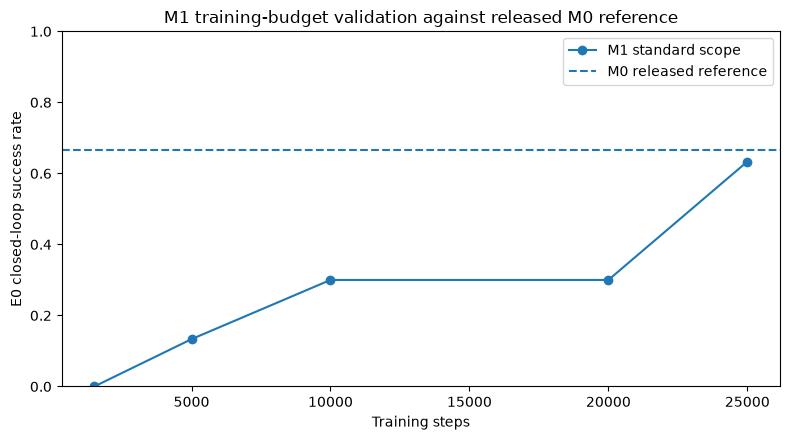

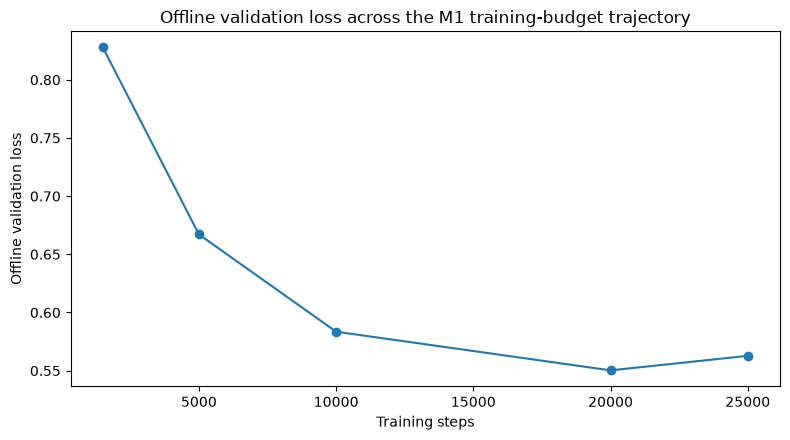

TRAINING-BUDGET CURVES: PASS


In [19]:
standard_budget_summary_df = (
    candidate_e0_summary_df[
        candidate_e0_summary_df[
            "scope"
        ]
        == "standard"
    ][
        [
            "candidate_id",
            "training_steps",
            "successes",
            "success_rate",
        ]
    ]
    .merge(
        offline_validation_df[
            [
                "candidate_id",
                "validation_loss",
            ]
        ],
        on="candidate_id",
        how="left",
        validate="one_to_one",
    )
    .sort_values(
        "training_steps"
    )
    .reset_index(
        drop=True
    )
)

display(
    standard_budget_summary_df
)

fig, ax = plt.subplots(
    figsize=(8, 4.5)
)

ax.plot(
    standard_budget_summary_df[
        "training_steps"
    ],
    standard_budget_summary_df[
        "success_rate"
    ],
    marker="o",
    label="M1 standard scope",
)

ax.axhline(
    M0_E0_SUCCESS_RATE,
    linestyle="--",
    label="M0 released reference",
)

ax.set_xlabel(
    "Training steps"
)

ax.set_ylabel(
    "E0 closed-loop success rate"
)

ax.set_ylim(
    0.0,
    1.0,
)

ax.set_title(
    "M1 training-budget validation against released M0 reference"
)

ax.legend()

fig.tight_layout()

budget_curve_path = (
    FIGURES_DIR
    / "m1_training_budget_e0_success.png"
)

fig.savefig(
    budget_curve_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()


fig, ax = plt.subplots(
    figsize=(8, 4.5)
)

ax.plot(
    standard_budget_summary_df[
        "training_steps"
    ],
    standard_budget_summary_df[
        "validation_loss"
    ],
    marker="o",
)

ax.set_xlabel(
    "Training steps"
)

ax.set_ylabel(
    "Offline validation loss"
)

ax.set_title(
    "Offline validation loss across the M1 training-budget trajectory"
)

fig.tight_layout()

offline_curve_path = (
    FIGURES_DIR
    / "m1_training_budget_offline_loss.png"
)

fig.savefig(
    offline_curve_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print("TRAINING-BUDGET CURVES: PASS")

## 20. Trainability-scope comparison at 25k steps

,candidate_id,scope,training_steps,episodes,successes,success_rate,validation_loss,trainable_parameters,trainable_fraction,training_minutes,peak_gpu_memory_gb
0,STD_25000,standard,25000.0,30,19,0.633333,0.562760,99880992,0.221935,61.004498,2.098712
1,BROAD_25000,broad,25000.0,30,14,0.466667,0.573359,392904096,0.873031,77.949194,5.704545


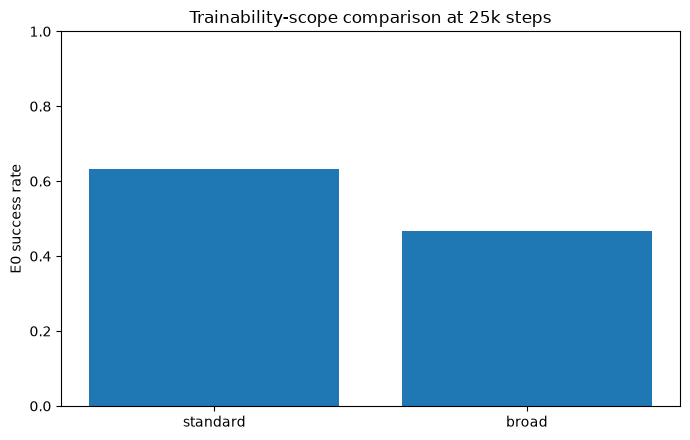

TRAINABILITY-SCOPE COMPARISON: PASS


In [20]:
scope_25k_df = (
    candidate_e0_summary_df[
        candidate_e0_summary_df[
            "candidate_id"
        ].isin(
            [
                "STD_25000",
                "BROAD_25000",
            ]
        )
    ][
        [
            "candidate_id",
            "scope",
            "training_steps",
            "episodes",
            "successes",
            "success_rate",
        ]
    ]
    .merge(
        offline_validation_df[
            [
                "candidate_id",
                "validation_loss",
            ]
        ],
        on="candidate_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        trainability_audit_df[
            [
                "scope",
                "trainable_parameters",
                "trainable_fraction",
                "training_minutes",
                "peak_gpu_memory_gb",
            ]
        ],
        on="scope",
        how="left",
        validate="many_to_one",
    )
)

display(
    scope_25k_df
)

fig, ax = plt.subplots(
    figsize=(7, 4.5)
)

ax.bar(
    scope_25k_df[
        "scope"
    ],
    scope_25k_df[
        "success_rate"
    ],
)

ax.set_ylim(
    0.0,
    1.0,
)

ax.set_ylabel(
    "E0 success rate"
)

ax.set_title(
    "Trainability-scope comparison at 25k steps"
)

fig.tight_layout()

scope_figure_path = (
    FIGURES_DIR
    / "trainability_scope_e0_success_25k.png"
)

fig.savefig(
    scope_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print("TRAINABILITY-SCOPE COMPARISON: PASS")

## 21. Predeclared adequacy gate and regime selection

A trainable candidate is considered **adequate for final robustness retraining** only if:

\[
SR_{candidate} \ge \max(0.20,\; 0.80 \times SR_{M0})
\]

This is a practical project gate, not a claim of statistical equivalence.

If several adequate candidates are within **one successful episode (3.33 percentage points)** of the best 30-episode screen, the lower-compute candidate is preferred.

This prevents automatically selecting the largest training budget when its practical gain is negligible.

In [21]:
selection_df = (
    candidate_e0_summary_df[
        candidate_e0_summary_df[
            "scope"
        ].isin(
            [
                "standard",
                "broad",
            ]
        )
    ]
    .merge(
        offline_validation_df[
            [
                "candidate_id",
                "validation_loss",
            ]
        ],
        on="candidate_id",
        how="left",
        validate="one_to_one",
    )
    .copy()
)

adequacy_threshold = max(
    ABSOLUTE_MIN_E0_SUCCESS,
    REFERENCE_RETENTION_TARGET
    * M0_E0_SUCCESS_RATE,
)

selection_df[
    "reference_retention_ratio"
] = (
    selection_df[
        "success_rate"
    ]
    / max(
        M0_E0_SUCCESS_RATE,
        1e-12,
    )
)

selection_df[
    "adequate"
] = (
    selection_df[
        "success_rate"
    ]
    >= adequacy_threshold
)

best_success_count = int(
    selection_df[
        "successes"
    ].max()
)

selection_df[
    "within_practical_tie"
] = (
    selection_df[
        "successes"
    ]
    >= (
        best_success_count
        - PRACTICAL_TIE_SUCCESS_COUNT
    )
)

adequate_df = (
    selection_df[
        selection_df[
            "adequate"
        ]
    ]
    .copy()
)

TRAINING_REGIME_READY = bool(
    not adequate_df.empty
)

selected_regime = None

if TRAINING_REGIME_READY:
    practically_best_df = (
        adequate_df[
            adequate_df[
                "successes"
            ]
            >= (
                adequate_df[
                    "successes"
                ].max()
                - PRACTICAL_TIE_SUCCESS_COUNT
            )
        ]
        .copy()
    )

    scope_rank = {
        "standard": 0,
        "broad": 1,
    }

    practically_best_df[
        "scope_rank"
    ] = practically_best_df[
        "scope"
    ].map(
        scope_rank
    )

    practically_best_df = (
        practically_best_df
        .sort_values(
            [
                "training_steps",
                "scope_rank",
                "validation_loss",
            ],
            ascending=[
                True,
                True,
                True,
            ],
        )
        .reset_index(
            drop=True
        )
    )

    selected_row = (
        practically_best_df.iloc[
            0
        ]
    )

    selected_regime = {
        "candidate_id": str(
            selected_row[
                "candidate_id"
            ]
        ),
        "scope": str(
            selected_row[
                "scope"
            ]
        ),
        "training_steps": int(
            selected_row[
                "training_steps"
            ]
        ),
        "e0_successes": int(
            selected_row[
                "successes"
            ]
        ),
        "e0_episodes": int(
            selected_row[
                "episodes"
            ]
        ),
        "e0_success_rate": float(
            selected_row[
                "success_rate"
            ]
        ),
        "m0_reference_success_rate": float(
            M0_E0_SUCCESS_RATE
        ),
        "reference_retention_ratio": float(
            selected_row[
                "reference_retention_ratio"
            ]
        ),
        "offline_validation_loss": float(
            selected_row[
                "validation_loss"
            ]
        ),
        "learning_rate": float(
            LEARNING_RATE
        ),
        "weight_decay": float(
            WEIGHT_DECAY
        ),
        "batch_size": int(
            BATCH_SIZE
        ),
        "seed_used_for_diagnostic": int(
            DIAGNOSTIC_SEED
        ),
        "selection_rule": (
            "Must pass the predeclared E0 adequacy gate; "
            "among candidates within one success of the best adequate "
            "30-episode screen, prefer fewer training steps, then the "
            "standard trainability scope, then lower offline validation loss."
        ),
    }


display(
    selection_df[
        [
            "candidate_id",
            "scope",
            "training_steps",
            "successes",
            "success_rate",
            "reference_retention_ratio",
            "validation_loss",
            "adequate",
        ]
    ].sort_values(
        [
            "adequate",
            "success_rate",
        ],
        ascending=[
            False,
            False,
        ],
    )
)

print()
print(
    "M0 E0 reference success:",
    f"{M0_E0_SUCCESS_RATE:.1%}",
)

print(
    "Adequacy threshold:",
    f"{adequacy_threshold:.1%}",
)

print(
    "Training regime ready:",
    TRAINING_REGIME_READY,
)

if selected_regime is not None:
    print()
    print(
        "SELECTED REGIME:",
        selected_regime[
            "candidate_id"
        ],
    )

    display(
        pd.DataFrame(
            [selected_regime]
        ).T.rename(
            columns={0: "Value"}
        )
    )

else:
    print()
    print(
        "NO CANDIDATE PASSED THE PREDECLARED ADEQUACY GATE."
    )

    print(
        "Do not launch final robustness retraining yet."
    )

,candidate_id,scope,training_steps,successes,success_rate,reference_retention_ratio,validation_loss,adequate
4,STD_25000,standard,25000.0,19,0.633333,0.95,0.562760,True
5,BROAD_25000,broad,25000.0,14,0.466667,0.70,0.573359,False
2,STD_10000,standard,10000.0,9,0.300000,0.45,0.583514,False
3,STD_20000,standard,20000.0,9,0.300000,0.45,0.550280,False
1,STD_5000,standard,5000.0,4,0.133333,0.20,0.667099,False
0,STD_1500,standard,1500.0,0,0.000000,0.00,0.827742,False



M0 E0 reference success: 66.7%
Adequacy threshold: 53.3%
Training regime ready: True

SELECTED REGIME: STD_25000


,Value
candidate_id,STD_25000
scope,standard
training_steps,25000
e0_successes,19
e0_episodes,30
e0_success_rate,0.633333
m0_reference_success_rate,0.666667
reference_retention_ratio,0.95
offline_validation_loss,0.56276
learning_rate,0.0001


## 22. Freeze the Notebook 06 retraining handoff when ready

In [22]:
regime_diagnostic_path = (
    METRICS_DIR
    / "training_regime_diagnostic.json"
)

diagnostic_payload = {
    "notebook": (
        "05_reference_control_and_training_budget_validation"
    ),
    "project_git_sha": PROJECT_GIT_SHA,
    "dataset_repo_id": DATASET_REPO_ID,
    "dataset_revision": DATASET_REVISION,
    "base_model_repo_id": BASE_MODEL_REPO_ID,
    "base_model_revision": BASE_MODEL_REVISION,
    "reference_model_repo_id": REFERENCE_MODEL_REPO_ID,
    "reference_model_revision": REFERENCE_MODEL_REVISION,
    "m0_task0_seed42_control_pass": bool(
        M0_TASK0_CONTROL_PASS
    ),
    "m0_e0_success_rate": float(
        M0_E0_SUCCESS_RATE
    ),
    "adequacy_threshold": float(
        adequacy_threshold
    ),
    "absolute_min_e0_success": float(
        ABSOLUTE_MIN_E0_SUCCESS
    ),
    "reference_retention_target": float(
        REFERENCE_RETENTION_TARGET
    ),
    "training_regime_ready": bool(
        TRAINING_REGIME_READY
    ),
    "selected_regime": (
        selected_regime
    ),
    "pilot_notebook04_status": (
        notebook04_summary[
            "status"
        ]
    ),
    "selection_uses_ood_results": False,
}

with open(
    regime_diagnostic_path,
    "w",
) as f:
    json.dump(
        diagnostic_payload,
        f,
        indent=2,
    )


NOTEBOOK06_HANDOFF_PATH = (
    EXPERIMENT_CONFIG_DIR
    / "notebook06_validated_retraining_handoff_v1.json"
)

if TRAINING_REGIME_READY:
    notebook06_handoff = {
        "source_notebook": (
            "05_reference_control_and_training_budget_validation"
        ),
        "training_regime": selected_regime,
        "dataset_repo_id": DATASET_REPO_ID,
        "dataset_revision": DATASET_REVISION,
        "split_file": notebook03_summary[
            "split_file"
        ],
        "split_sha256": notebook03_summary[
            "split_sha256"
        ],
        "base_model_repo_id": BASE_MODEL_REPO_ID,
        "base_model_revision": BASE_MODEL_REVISION,
        "language_table": (
            "configs/experiments/"
            "libero_spatial_language_augmentations_v1.csv"
        ),
        "final_models": {
            "M1": {
                "seeds": [
                    42,
                    123,
                    2026,
                ],
                "language_levels": [
                    "L0",
                ],
                "environment_augmentation": False,
            },
            "M2-L": {
                "seeds": [
                    42,
                ],
                "language_levels": [
                    "L0",
                    "L1",
                    "L2",
                ],
                "environment_augmentation": False,
            },
            "M2-E": {
                "seeds": [
                    42,
                ],
                "language_levels": [
                    "L0",
                ],
                "environment_augmentation": True,
            },
            "M2-LE": {
                "seeds": [
                    42,
                    123,
                    2026,
                ],
                "language_levels": [
                    "L0",
                    "L1",
                    "L2",
                ],
                "environment_augmentation": True,
            },
        },
        "final_evaluation_policy": (
            "Notebook 06 retrains the frozen model set. "
            "Notebook 07 performs the definitive ID/OOD evaluation. "
            "Notebook 04 remains the pilot diagnostic evaluation."
        ),
    }

    with open(
        NOTEBOOK06_HANDOFF_PATH,
        "w",
    ) as f:
        json.dump(
            notebook06_handoff,
            f,
            indent=2,
        )

    print(
        "Notebook 06 handoff frozen:",
        NOTEBOOK06_HANDOFF_PATH,
    )

else:
    if NOTEBOOK06_HANDOFF_PATH.exists():
        NOTEBOOK06_HANDOFF_PATH.unlink()

    print(
        "Notebook 06 handoff NOT created because the adequacy gate did not pass."
    )


print(
    "Diagnostic summary:",
    regime_diagnostic_path,
)

Notebook 06 handoff frozen: /home/leeming/projects/deep-learning-vla-robustness/configs/experiments/notebook06_validated_retraining_handoff_v1.json
Diagnostic summary: /home/leeming/projects/deep-learning-vla-robustness/results/metrics/training_regime_validation/training_regime_diagnostic.json


## 23. Final technical status and decision gate

In [23]:
technical_checks = {
    "Notebook 01 known control prerequisite":
        bool(
            notebook01_summary[
                "g0_pass"
            ]
        ),

    "Notebook 03 training prerequisite":
        (
            notebook03_summary[
                "status"
            ]
            == "PASS"
        ),

    "Notebook 04 pilot prerequisite":
        (
            notebook04_summary[
                "status"
            ]
            == "PASS"
        ),

    "Pilot floor effect documented":
        bool(
            pilot_floor_effect
        ),

    "M0 task-0 seed-42 control":
        bool(
            M0_TASK0_CONTROL_PASS
        ),

    "M0 30-episode E0 reference":
        (
            len(
                m0_e0_df
            )
            == (
                10
                * E0_EPISODES_PER_TASK
            )
        ),

    "Standard 25k trajectory":
        (
            standard_result[
                "status"
            ]
            == "PASS"
        ),

    "Broad 25k trajectory":
        (
            broad_result[
                "status"
            ]
            == "PASS"
        ),

    "All standard milestone checkpoints":
        (
            len(
                standard_budget_summary_df
            )
            == len(
                STANDARD_CHECKPOINT_STEPS
            )
        ),

    "All trainable candidates screened":
        (
            len(
                selection_df
            )
            == (
                len(
                    STANDARD_CHECKPOINT_STEPS
                )
                + 1
            )
        ),

    "Offline validation finite":
        bool(
            np.isfinite(
                offline_validation_df[
                    "validation_loss"
                ]
            ).all()
        ),

    "E0 screening complete":
        bool(
            (
                candidate_e0_summary_df[
                    "episodes"
                ]
                == (
                    10
                    * E0_EPISODES_PER_TASK
                )
            ).all()
        ),

    "Training-regime diagnostic saved":
        regime_diagnostic_path.exists(),
}

technical_checks = {
    key: bool(
        value
    )
    for key, value
    in technical_checks.items()
}

technical_status_df = pd.DataFrame(
    [
        {
            "check": key,
            "status": (
                "PASS"
                if value
                else "FAIL"
            ),
        }
        for key, value
        in technical_checks.items()
    ]
)

display(
    technical_status_df
)

NOTEBOOK_05_TECHNICAL_PASS = bool(
    all(
        technical_checks.values()
    )
)


if TRAINING_REGIME_READY:
    DECISION_GATE = (
        "READY_FOR_VALIDATED_FINAL_RETRAINING"
    )

else:
    DECISION_GATE = (
        "NOT_READY_REQUIRES_TRAINING_METHOD_REVIEW"
    )


notebook05_summary = {
    "notebook": (
        "05_reference_control_and_training_budget_validation"
    ),
    "technical_status": (
        "PASS"
        if NOTEBOOK_05_TECHNICAL_PASS
        else "FAIL"
    ),
    "decision_gate": DECISION_GATE,
    "training_regime_ready": bool(
        TRAINING_REGIME_READY
    ),
    "m0_e0_success_rate": float(
        M0_E0_SUCCESS_RATE
    ),
    "adequacy_threshold": float(
        adequacy_threshold
    ),
    "selected_regime": (
        selected_regime
    ),
    "technical_checks": technical_checks,
    "candidate_registry": str(
        candidate_registry_path.relative_to(
            REPO_ROOT
        )
    ),
    "diagnostic_summary": str(
        regime_diagnostic_path.relative_to(
            REPO_ROOT
        )
    ),
    "notebook06_handoff": (
        str(
            NOTEBOOK06_HANDOFF_PATH.relative_to(
                REPO_ROOT
            )
        )
        if NOTEBOOK06_HANDOFF_PATH.exists()
        else None
    ),
}

notebook05_summary_path = (
    METRICS_DIR
    / "notebook05_summary.json"
)

with open(
    notebook05_summary_path,
    "w",
) as f:
    json.dump(
        notebook05_summary,
        f,
        indent=2,
    )


print("=" * 76)

print(
    "NOTEBOOK 05 — FINAL STATUS"
)

print("=" * 76)

for key, value in technical_checks.items():
    print(
        f"{key:<58} "
        f"{'PASS' if value else 'FAIL'}"
    )

print("-" * 76)

print(
    f"{'NOTEBOOK 05 TECHNICAL STATUS':<58} "
    f"{'PASS' if NOTEBOOK_05_TECHNICAL_PASS else 'FAIL'}"
)

print(
    f"{'TRAINING REGIME DECISION':<58} "
    f"{DECISION_GATE}"
)

print("-" * 76)

assert NOTEBOOK_05_TECHNICAL_PASS

print()

if TRAINING_REGIME_READY:
    print(
        "A training regime passed the predeclared E0 adequacy gate."
    )

    print(
        "Ready for Notebook 06: validated final retraining."
    )

else:
    print(
        "The diagnostic completed successfully, but no training regime "
        "recovered sufficient E0 performance relative to M0."
    )

    print(
        "Do NOT launch final robustness retraining yet."
    )

print()
print(
    "Summary saved:",
    notebook05_summary_path,
)

,check,status
0,Notebook 01 known control prerequisite,PASS
1,Notebook 03 training prerequisite,PASS
2,Notebook 04 pilot prerequisite,PASS
3,Pilot floor effect documented,PASS
4,M0 task-0 seed-42 control,PASS
5,M0 30-episode E0 reference,PASS
6,Standard 25k trajectory,PASS
7,Broad 25k trajectory,PASS
8,All standard milestone checkpoints,PASS
9,All trainable candidates screened,PASS


NOTEBOOK 05 — FINAL STATUS
Notebook 01 known control prerequisite                     PASS
Notebook 03 training prerequisite                          PASS
Notebook 04 pilot prerequisite                             PASS
Pilot floor effect documented                              PASS
M0 task-0 seed-42 control                                  PASS
M0 30-episode E0 reference                                 PASS
Standard 25k trajectory                                    PASS
Broad 25k trajectory                                       PASS
All standard milestone checkpoints                         PASS
All trainable candidates screened                          PASS
Offline validation finite                                  PASS
E0 screening complete                                      PASS
Training-regime diagnostic saved                           PASS
----------------------------------------------------------------------------
NOTEBOOK 05 TECHNICAL STATUS                               PASS


## 24. Interpretation framework for the report

Notebook 05 should be described as a **diagnostic correction**, not as post-hoc result shopping.

The logic is:

1. Notebook 04 completed the planned pilot evaluation.
2. The pilot exposed an absolute-performance floor effect.
3. The released M0 checkpoint was introduced as an evaluator control.
4. Training duration and parameter trainability were then varied using **E0 only**.
5. OOD pilot outcomes were explicitly excluded from configuration selection.
6. A predeclared adequacy gate determined whether the training regime was ready for final robustness retraining.

This is preferable to silently discarding Notebook 04 or simply increasing the number of training steps until a desired OOD result appears.

### Next notebooks

If the decision gate is `READY_FOR_VALIDATED_FINAL_RETRAINING`:

- **Notebook 06 — Validated Final Retraining**
  - retrain M1 and M2-LE across seeds 42 / 123 / 2026,
  - retrain M2-L and M2-E at seed 42,
  - use the frozen Notebook 05 regime only.

- **Notebook 07 — Definitive Robustness Evaluation**
  - rerun the final ID/OOD matrix on the validated checkpoints,
  - keep Notebook 04 as pilot evidence,
  - make the final research claims only from Notebook 07.